# Deep Network Development · Autumn 2026
## Week 7 Practical — Regression, Binary Classification, and Multiclass Classification with PyTorch

**Dataset:** [Student Lifestyle Dataset](https://www.kaggle.com/datasets/steve1215rogg/student-lifestyle-dataset)  
**Libraries:** Pandas, NumPy, PyTorch, Matplotlib, and scikit-learn

### Learning objectives
By the end of this practical, you should be able to:
- Prepare features and targets for three supervised learning tasks.
- Construct a custom PyTorch `Dataset` and load batches with `DataLoader`.
- Build, train, and evaluate simple feedforward neural networks.
- Select suitable output layers and loss functions for regression and classification.
- Interpret learning curves, test losses, and confusion matrices.

We will reuse a similar training workflow across all three tasks. Pay attention to what changes in the target representation, model output, and loss function.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Load the dataset

Read the CSV file into a Pandas DataFrame and inspect its contents. The file should be located in the same working directory as this notebook. The first column is treated as the row index.


In [2]:
df = pd.read_csv('student_lifestyle_dataset.csv', header=0, index_col=0)

In [3]:
df

,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
Student_ID,,,,,,,
1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate
2,5.3,3.5,8.0,4.2,3.0,2.75,Low
3,5.1,3.9,9.2,1.2,4.6,2.67,Low
4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate
5,8.1,0.6,6.5,2.2,6.6,3.51,High
...,...,...,...,...,...,...,...
1996,6.5,0.2,7.4,2.1,7.8,3.32,Moderate
1997,6.3,2.8,8.8,1.5,4.6,2.65,Moderate
1998,6.2,0.0,6.2,0.8,10.8,3.14,Moderate


## 2. Explore the data

Inspect the column types, dataset dimensions, and missing values. Before training a model, identify which variables are numerical, which are categorical, and which column will serve as the prediction target.


In [4]:
df.dtypes

Study_Hours_Per_Day                float64
Extracurricular_Hours_Per_Day      float64
Sleep_Hours_Per_Day                float64
Social_Hours_Per_Day               float64
Physical_Activity_Hours_Per_Day    float64
GPA                                float64
Stress_Level                        object
dtype: object

In [5]:
df.shape

(2000, 7)

In [6]:
df.isna().sum(axis=0)

Study_Hours_Per_Day                0
Extracurricular_Hours_Per_Day      0
Sleep_Hours_Per_Day                0
Social_Hours_Per_Day               0
Physical_Activity_Hours_Per_Day    0
GPA                                0
Stress_Level                       0
dtype: int64

## 3. Encode the categorical stress levels

Neural networks require numerical tensors. Convert the stress categories into integer labels: **Low = 0**, **Moderate = 1**, and **High = 2**. These values identify categories; they are not measurements of stress severity on a continuous scale.


In [7]:
df['Stress_Level'] = df['Stress_Level'].map({'Low': 0, 'Moderate': 1, 'High': 2})

## 4. Predict GPA — regression

Our first task is to predict a **continuous value**, GPA, from five lifestyle features. The model will produce a single numerical prediction per student. We will train it using **mean squared error (MSE)**, which penalizes larger prediction errors more heavily.


### 4.1 Prepare the dataset and data loaders

A custom PyTorch `Dataset` specifies how individual feature–target pairs are retrieved. A `DataLoader` groups those pairs into batches for training and evaluation.

We split the observations into **60% training, 20% validation, and 20% testing**:
- **Training:** updates model parameters.
- **Validation:** monitors generalization during training.
- **Test:** provides a final evaluation on held-out observations.

For this task, the inputs have five features and the target has one value per student.


In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

In [9]:
class StudentLifeStyleDataset(Dataset):
    def __init__(self, features, target):
        self.features = features
        self.target = target

    def __len__(self):
        return self.features.shape[0]

    def __getitem__(self, idx):
        return torch.Tensor(self.features[idx]), torch.Tensor(self.target[idx])

In [10]:
df.columns.values

array(['Study_Hours_Per_Day', 'Extracurricular_Hours_Per_Day',
       'Sleep_Hours_Per_Day', 'Social_Hours_Per_Day',
       'Physical_Activity_Hours_Per_Day', 'GPA', 'Stress_Level'],
      dtype=object)

In [11]:
dataset = df.to_numpy()

FEATURE_COL_IDXS = [0, 1, 2, 3, 4]
TARGET_COL_IDX = [5]

print(f'feature_cols num: {dataset.shape}')

feature_cols num: (2000, 7)


In [12]:
train_set, validation_test_set = train_test_split(dataset, train_size=0.6, random_state=42, shuffle=True)
validation_set, test_set = train_test_split(validation_test_set, test_size=0.5)

In [13]:
train_dataset = StudentLifeStyleDataset(train_set[:, FEATURE_COL_IDXS], train_set[:, TARGET_COL_IDX])
validation_dataset = StudentLifeStyleDataset(validation_set[:, FEATURE_COL_IDXS], validation_set[:, TARGET_COL_IDX])
test_dataset = StudentLifeStyleDataset(test_set[:, FEATURE_COL_IDXS], test_set[:, TARGET_COL_IDX])


train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(validation_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

### 4.2 Define the regression network

The feedforward network maps **five input features → four hidden units with ReLU → one output**. The final layer has no activation function because GPA is a continuous prediction. The output is not restricted to a fixed interval by the architecture.


In [14]:
import torch.nn as nn
import torch.nn.functional as f
import torch.optim as optim

In [15]:
class RegressionModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(5, 4),
            nn.ReLU(),
            nn.Linear(4, 1) # One output neuron, because we are predicting one value
        )

    def forward(self, x):
        return self.model(x)

### 4.3 Train and validate the model

For each mini-batch, the training loop computes predictions, measures MSE, calculates gradients with backpropagation, and updates the network weights using stochastic gradient descent (SGD). After each epoch, we evaluate the model on the validation set **without updating its weights**.

Plot training and validation loss to inspect convergence and possible overfitting. A decreasing training loss alone does not guarantee that the model generalizes well.


In [16]:
torch.manual_seed(43)

num_epochs = 100

reg_model = RegressionModel() # Initialize model
mse_loss = nn.MSELoss() # Define Loss function
optimizer = optim.SGD(reg_model.parameters(), lr=0.01) # Setup optimizer

train_losses = []
valid_losses = []

for epoch in range(num_epochs):
    
    reg_model.train() # Switch model to train mode

    losses = []
    
    for i, data in enumerate(train_loader):
        # Every data instance is an input + label pair
        inputs, label = data

        # Zero your gradients for every batch!
        optimizer.zero_grad()

        # Make predictions for this batch
        prediction = reg_model(inputs)

        # Compute the loss and its gradients
        train_loss = mse_loss(prediction, label)
        train_loss.backward() # Backpropagate

        # Adjust learning weights
        optimizer.step()

        # Accumulate losses
        losses.append(train_loss.item())

    train_losses.append(np.mean(losses))
    losses = []

    reg_model.eval() # Switch model to evaluation mode
    
    with torch.no_grad(): # Turn of gradiant calculation
        for i, data in enumerate(val_loader):
            inputs, label = data
            prediction = reg_model(inputs)
            valid_loss = mse_loss(prediction, label)
            losses.append(valid_loss.item())

    valid_losses.append(np.mean(losses))

    print(f'Train Loss: {train_losses[-1]:.4f}, Valid Loss: {valid_losses[-1]:.4f}')


Train Loss: 0.4454, Valid Loss: 0.0747
Train Loss: 0.0663, Valid Loss: 0.0641
Train Loss: 0.0593, Valid Loss: 0.0732
Train Loss: 0.0520, Valid Loss: 0.0543
Train Loss: 0.0501, Valid Loss: 0.0520
Train Loss: 0.0496, Valid Loss: 0.0485
Train Loss: 0.0458, Valid Loss: 0.0471
Train Loss: 0.0460, Valid Loss: 0.0556
Train Loss: 0.0473, Valid Loss: 0.0469
Train Loss: 0.0427, Valid Loss: 0.0439
Train Loss: 0.0430, Valid Loss: 0.0482
Train Loss: 0.0424, Valid Loss: 0.0428
Train Loss: 0.0425, Valid Loss: 0.0496
Train Loss: 0.0418, Valid Loss: 0.0428
Train Loss: 0.0422, Valid Loss: 0.0431
Train Loss: 0.0428, Valid Loss: 0.0485
Train Loss: 0.0413, Valid Loss: 0.0456
Train Loss: 0.0422, Valid Loss: 0.0417
Train Loss: 0.0423, Valid Loss: 0.0444
Train Loss: 0.0428, Valid Loss: 0.0426
Train Loss: 0.0410, Valid Loss: 0.0433
Train Loss: 0.0415, Valid Loss: 0.0424
Train Loss: 0.0436, Valid Loss: 0.0411
Train Loss: 0.0406, Valid Loss: 0.0411
Train Loss: 0.0416, Valid Loss: 0.0478
Train Loss: 0.0422, Valid

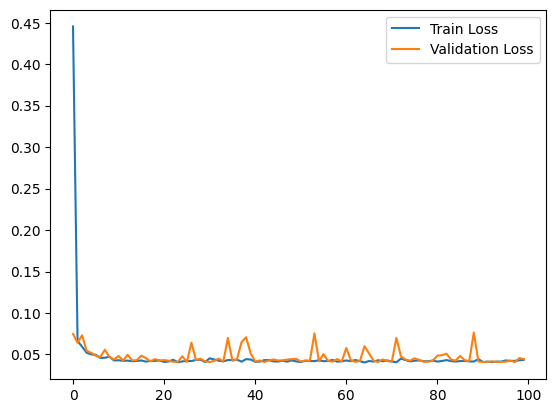

In [17]:
plt.plot(train_losses, label="Train Loss")
plt.plot(valid_losses, label="Validation Loss")
plt.legend()

### 4.4 Evaluate on the test set

Calculate the MSE on the held-out test set. Lower MSE indicates smaller squared errors, but its magnitude should be interpreted relative to the scale of GPA. The test set should not be used to select model settings during training.


In [18]:
test_losses = []

with torch.no_grad():
    for i, data in enumerate(test_loader):
        inputs, label = data
        prediction = reg_model(inputs)
        loss = mse_loss(prediction, label)
        test_losses.append(loss.item())

print(f'Test MSE: {np.mean(test_losses):.4f}')

Test MSE: 0.0466


## 5. Predict high stress — binary classification

We now ask a yes/no question: **Does a student belong to the High Stress category?** Both Low and Moderate are treated as *not High*. Unlike regression, the target has only two possible values: 0 or 1.


To adapt the previous workflow for binary classification:

1. **Recode the target:** assign **1** to High Stress and **0** to both Low and Moderate Stress.
2. **Change the output layer:** use one output neuron followed by a `Sigmoid`, producing a value between 0 and 1. Interpret this value as the model's estimated probability of High Stress. The notebook predicts High Stress when the probability is **greater than 0.5**.
3. **Change the loss:** use binary cross-entropy (`BCELoss`) with the sigmoid probability output. Alternatively, `BCEWithLogitsLoss` accepts raw logits and applies the sigmoid operation internally; that alternative would require changing the model's final layer.

The training and validation steps otherwise follow the same general pattern as in regression.


In [19]:
FEATURE_COL_IDXS = [0, 1, 2, 3, 4]
TARGET_COL_IDX = [6]

In [20]:
dataset_copy = dataset.copy()

### 5.1 Encode the binary labels

Create a new target array from the original stress categories. Confirm that it has the intended shape and that each observation has a binary label before constructing the data loaders.


In [21]:
labels = (dataset_copy[:, TARGET_COL_IDX] == 2).astype(np.int64) # 2 = High
print(labels.shape)

binclass_dataset = np.concatenate([dataset_copy[:, FEATURE_COL_IDXS], labels], axis=1)

(2000, 1)


In [22]:
binclass_dataset.shape

(2000, 6)

In [23]:
train_set, validation_test_set = train_test_split(binclass_dataset, train_size=0.6, random_state=42, shuffle=True)
validation_set, test_set = train_test_split(validation_test_set, test_size=0.5)

In [24]:
train_dataset = StudentLifeStyleDataset(train_set[:, :-1], train_set[:, -1:])
validation_dataset = StudentLifeStyleDataset(validation_set[:, :-1], validation_set[:, -1:])
test_dataset = StudentLifeStyleDataset(test_set[:, :-1], test_set[:, -1:])


train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(validation_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=1)

In [25]:
class BinaryClassificationModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(5, 4),
            nn.ReLU(),
            nn.Linear(4, 1), # One output neuron because we are predicting 0 or 1 value
            nn.Sigmoid() # Enforce 0 and 1 bounded values (if value >0.5 we consider it as 1)
        )

    def forward(self, x):
        return self.model(x)

In [26]:
torch.manual_seed(42)

num_epochs = 100

bincl_model = BinaryClassificationModel()
bce_loss = nn.BCELoss()
optimizer = optim.SGD(bincl_model.parameters(), lr=0.01)

train_losses = []
valid_losses = []

for epoch in range(num_epochs):
    
    bincl_model.train()

    losses = []
    
    for i, data in enumerate(train_loader):
        # Every data instance is an input + label pair
        inputs, label = data

        # Zero your gradients for every batch!
        optimizer.zero_grad()

        # Make predictions for this batch
        prediction = bincl_model(inputs)

        # Compute the loss and its gradients
        train_loss = bce_loss(prediction, label)
        train_loss.backward()

        # Adjust learning weights
        optimizer.step()

        # Accumulate losses
        losses.append(train_loss.item())

    train_losses.append(np.mean(losses))
    losses = []

    bincl_model.eval()
    
    with torch.no_grad():
        for i, data in enumerate(val_loader):
            inputs, label = data
            prediction = bincl_model(inputs)
            valid_loss = bce_loss(prediction, label)
            losses.append(valid_loss.item())

    valid_losses.append(np.mean(losses))

    print(f'Train Loss: {train_losses[-1]:.4f}, Valid Loss: {valid_losses[-1]:.4f}')

Train Loss: 0.8061, Valid Loss: 0.7193
Train Loss: 0.6842, Valid Loss: 0.6680
Train Loss: 0.6540, Valid Loss: 0.6332
Train Loss: 0.6294, Valid Loss: 0.6045
Train Loss: 0.6036, Valid Loss: 0.5764
Train Loss: 0.5744, Valid Loss: 0.5430
Train Loss: 0.5433, Valid Loss: 0.5080
Train Loss: 0.5099, Valid Loss: 0.4934
Train Loss: 0.4794, Valid Loss: 0.4498
Train Loss: 0.4513, Valid Loss: 0.4194
Train Loss: 0.4300, Valid Loss: 0.3894
Train Loss: 0.4087, Valid Loss: 0.3811
Train Loss: 0.3925, Valid Loss: 0.3559
Train Loss: 0.3814, Valid Loss: 0.3391
Train Loss: 0.3717, Valid Loss: 0.3310
Train Loss: 0.3618, Valid Loss: 0.3240
Train Loss: 0.3564, Valid Loss: 0.3127
Train Loss: 0.3514, Valid Loss: 0.3074
Train Loss: 0.3427, Valid Loss: 0.3067
Train Loss: 0.3465, Valid Loss: 0.3077
Train Loss: 0.3415, Valid Loss: 0.2979
Train Loss: 0.3352, Valid Loss: 0.2924
Train Loss: 0.3348, Valid Loss: 0.2938
Train Loss: 0.3302, Valid Loss: 0.2892
Train Loss: 0.3310, Valid Loss: 0.3007
Train Loss: 0.3326, Valid

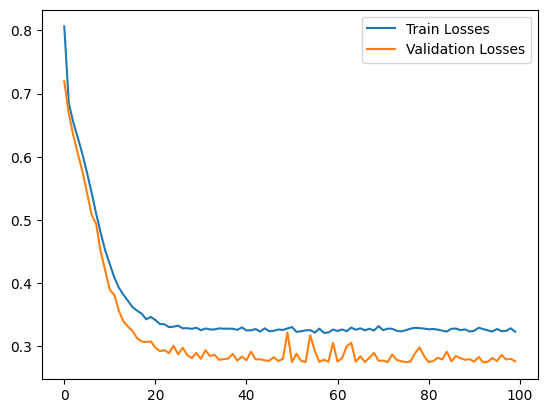

In [27]:
plt.plot(train_losses, label='Train Losses')
plt.plot(valid_losses, label='Validation Losses')
plt.legend()

### 5.2 Evaluate binary predictions with a confusion matrix

Convert predicted probabilities into class labels using the **0.5 threshold**, then compare them with the true labels. A confusion matrix summarizes the four possible outcomes: **true positives (TP)**, **false positives (FP)**, **true negatives (TN)**, and **false negatives (FN)**.


In this task, the **positive** class is High Stress (1). A **false negative** is a High Stress student predicted as not High; a **false positive** is a Low or Moderate Stress student predicted as High. Inspect both the overall accuracy and the types of mistakes the model makes.


In [28]:
test_losses = []
labels = []
predictions = []

bincl_model.eval()

with torch.no_grad():
    for i, data in enumerate(test_loader):
        inputs, label = data
        labels.append(label.numpy().astype(int))
        prediction = bincl_model(inputs)
        predictions.append((prediction > 0.5).numpy().astype(int))
        loss = bce_loss(prediction, label)
        test_losses.append(loss.item())



accuracy = (np.array(predictions) == np.array(labels)).mean()

print(f'Test BCE Loss: {np.mean(test_losses):.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

Test BCE Loss: 0.3408
Test Accuracy: 0.8500


In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [30]:
conf_matrix = confusion_matrix(np.array(labels).flatten(), np.array(predictions).flatten())

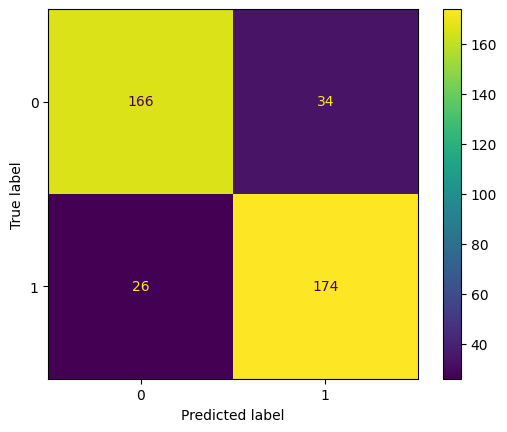

In [31]:
disp = ConfusionMatrixDisplay(conf_matrix)
disp.plot()

## 6. Predict all stress levels — multiclass classification

Our final supervised task predicts one of **three mutually exclusive classes**: Low, Moderate, or High Stress. Every observation belongs to exactly one category, and the network must choose among all three.


To adapt the classification workflow:

1. **Represent the targets:** this notebook uses **one-hot vectors**, with one entry for each class. PyTorch's `CrossEntropyLoss` also accepts integer class indices, which are commonly preferred.
2. **Change the output layer:** produce **three unnormalized scores (logits)**, one per class. Do **not** apply Softmax inside the model before passing these logits to `CrossEntropyLoss`.
3. **Change the loss:** use `CrossEntropyLoss`, which supports either integer class indices or floating-point class-probability targets, including one-hot vectors. For prediction, `Softmax` can convert logits to probabilities, and the class with the highest score is selected.

For a batch of $N$ students, the model outputs a tensor of shape **$(N, 3)$**. The one-hot targets used here have the same shape.


In [32]:
FEATURE_COL_IDXS = [0, 1, 2, 3, 4]
TARGET_COL_IDXS = [5, 6, 7]

In [33]:
dataset_copy = dataset.copy()

### 6.1 Encode the multiclass labels

We will use one-hot encoding to illustrate how a target can represent three possible classes. Each row contains exactly one 1 and two 0s.

**Student exercise:** Complete the blank code cells from this point onward, including data preparation, model training, evaluation, and the bonus analysis.

The class mapping is:

| Stress level | Class index | One-hot target |
|---|---:|---|
| Low | 0 | `[1, 0, 0]` |
| Moderate | 1 | `[0, 1, 0]` |
| High | 2 | `[0, 0, 1]` |

**PyTorch note:** One-hot encoding is valid here but is **not required** by `CrossEntropyLoss`. Integer targets such as `0`, `1`, or `2` also work, with a different target shape and dtype.


Try implementing one-hot encoding using NumPy operations.

Alternatively, implement one-hot encoding with `torch.nn.functional.one_hot`.

### 6.2 Prepare dataloaders and train model

### 6.3 Examine the multiclass confusion matrix

The confusion matrix has one row and one column for each class. In scikit-learn's default convention, **rows are true classes** and **columns are predicted classes**. Values on the diagonal are correct predictions; off-diagonal values identify which stress levels the model confuses.


Compare the errors across Low, Moderate, and High Stress. Are certain pairs of categories confused more frequently? Keep in mind that raw counts also depend on how many examples of each class occur in the test set.


## 7. Bonus task — One-feature-at-a-time sensitivity analysis

Explore how the trained **binary classification model's estimated probability of High Stress** changes as individual input features vary.

1. Start with an input vector containing the **mean value of each feature**.
2. Choose one feature and vary it across 10 values between its observed minimum and maximum.
3. Keep all remaining features fixed at their means, and record the model's predicted probability.
4. Repeat for every feature and compare the resulting curves.

**Interpretation:** These plots illustrate **model sensitivity**, not causal effects. Some combinations of feature values may also be unrealistic, because the method changes one feature independently of the others.
